# Exploring **CLMS HR-Water, Snow and Ice (WSI)** — A Jupyter Notebook to Illustrate the Ice Products

This notebook is the companion to the HR-WSI **snow** webinar notebook, focused this time on the **ice** products of the HR-WSI portfolio: Water and Ice Cover (WIC S1, WIC S2) and Ice Cover Duration (ICD).

**Data access is intentionally kept brief here.** The full walkthrough of the CDSE OData API — authentication, filtering, downloading, cloud-cover filters, AOI-based search — was covered in detail in the HR-WSI Snow webinar notebook. If you have not seen it, we recommend starting there: `HR-WSI-CDR-288-MAG_HR-WSI_snow_webinar_V1.ipynb`. This notebook reuses the same helper functions without re-deriving them, and focuses on what the ice products actually show and how to work with them.

This notebook is organized into four short live sections and an appendix for self-study:
- **Section 1** — Get ice data for an area of interest (fast recap of the relevant section from the snow notebook)
- **Section 2** — Visualize and compare WIC S1 vs. WIC S2
- **Section 3** — Filter observations using the QAFLAGS quality layer
- **Section 4** — Application: estimate freeze-up and break-up dates for a lake
- **Appendix** (not presented live, for later exploration) — Ice Cover Duration (ICD) and a note on the Aggregated Water and Ice Cover (AWIC) product

**Authors**: Cemal Melih Tanis (FMI), Miriam Kosmale (FMI)

**Prerequisites**
Before starting, please complete the following steps:
- Create an account on the CDSE interface: https://dataspace.copernicus.eu/
- Access your CDSE JupyterLab environment: https://dataspace.copernicus.eu/analyse/jupyterlab and select a Medium or Large server.

*NB*: Files stored in the CDSE JupyterLab default working directory ('home') are not persistent and will be deleted automatically when the session ends. This is why this notebook uses 'mystorage' folder as the parent working directory.
- In the left panel, create a new folder inside the 'mystorage' directory if it isn't there already (`mystorage` itself is provided by the hub, but the subfolder for this notebook is not).
- Upload this Jupyter notebook by dragging and dropping it into the newly created folder.
- Upload to the same folder a text file named `credentials.txt` containing your authentication credentials in the following format:

```
username=email@address.com
password=mypassword
```

- Download the EU-Hydro reference dataset (used in Section 4 to define lake boundaries) from https://land.copernicus.eu/en/products/eu-hydro/eu-hydro-river-network-database#download, and upload it into an `auxiliary` subfolder inside your notebook folder (create it if it doesn't exist yet — the notebook keeps all downloaded/reference data out of the main folder: WIC/ICD products go in `products`, EU-Hydro goes in `auxiliary`). A few things to know before downloading:
  - EU-Hydro is distributed both as **one file per major European river basin** and as a single package bundling **all basins for the whole of Europe**. We recommend downloading only the basin(s) containing the lake(s) you plan to use, rather than the whole-Europe package, since the full dataset runs into several GB while a single basin is much smaller. For this notebook, as currently written, you only need **either** the single-basin file covering the **Kemi** river basin **or** the whole-Europe package.
  - The lake polygons you need live in the **`InlandWater` layer** inside the downloaded geodatabase/geopackage — it's one of twelve feature classes bundled together (points, lines, and polygons for rivers, canals, ditches, and water bodies), and `InlandWater` is specifically defined as "a large body of water entirely surrounded by land."
  - The lake's name is stored in the `NAM` attribute of that layer, and its unique ID is stored in `LAKID` — see the note in Section 4 on why `LAKID` matters.
- Open this notebook from the file browser in the Jupyter Hub UI (the kernel selector is only visible once the notebook is open), then select the Geo Science kernel from the kernel selector in the top-right corner of the interface.

Once you have completed the steps above, your folder structure should be similar to:

```
mystorage/notebooks/2026-10_ice_webinar/
└── auxiliary/
    └── euhydro_kemi_v013_FGDB.zip        (or EU_hydro_fgdb_eu.zip for the whole-Europe package)
├── credentials.txt
├── HR-WSI-ice-webinar.ipynb
├── README.md
└── ypnb_env.yaml
```


## Environment check

The CDSE JupyterLab environment ships with a ready-made geospatial Python setup that already covers most of what we need. The cell below sets the working directory, checks that everything required is present, and installs anything missing via `pip`, so the notebook is portable to other environments too.

**Important**: JupyterLab on CDSE opens notebooks with the kernel's working directory set to your home folder, not the folder the notebook file itself lives in. Update `WORKING_DIR` below to the folder (inside `mystorage`, so it persists across sessions) where you placed this notebook, your `credentials.txt`, and the EU-Hydro file.

**Running locally (outside CDSE)**:
- **`fiona` wheels**: `pip install fiona` only works without a system GDAL if a prebuilt wheel exists for your Python version. Fiona 1.10.x requires Python 3.8+ and GDAL 3.4+ (its wheels bundle their own GDAL, 3.9.1), but has no wheels for very new Python releases (e.g. 3.14) — use Python 3.11–3.13. Otherwise pip builds from source and fails without `gdal-config`. CDSE (Python 3.11, GDAL 3.9.2) is fine. **Suggested method**: create a new conda env with Python 3.11 (`conda create -n webinar python=3.11`, then `conda activate webinar` and `pip install ipykernel`), and select that env's kernel in the notebook *before* running the cell below.
- **VS Code progress bars**: if `tqdm` progress bars fail to render with an `ipywidgetsKernel` error, install `ipywidgets` (included below), clear outputs, restart the kernel, and add `"jupyter.widgetScriptSources": ["jsdelivr.com", "unpkg.com"]` to your VS Code user `settings.json`.


In [1]:
import importlib
import subprocess
import sys
import os

# On CDSE JupyterLab, notebook + inputs live under mystorage (persistent storage).
# When running locally (e.g. via VS Code/WSL), stay in the current directory instead.
CDSE_WORKING_DIR = "mystorage/notebooks/2026-10_ice_webinar"
WORKING_DIR = CDSE_WORKING_DIR if os.path.isdir(CDSE_WORKING_DIR) else "."
os.chdir(WORKING_DIR)

# All downloaded products are extracted here, kept separate from the notebook and input files
PRODUCTS_DIR = "products"
os.makedirs(PRODUCTS_DIR, exist_ok=True)

# Reference/auxiliary inputs (currently just the EU-Hydro download used in Section 4) live here too,
# so nothing but this notebook and credentials.txt sits loose in the working directory.
AUX_DIR = "auxiliary"
os.makedirs(AUX_DIR, exist_ok=True)

required_packages = {
    "ipykernel": "ipykernel",
    "ipywidgets": "ipywidgets",  # provides IProgress, needed by tqdm.auto progress bars
    "requests": "requests",
    "pandas": "pandas",
    "geopandas": "geopandas",
    "fiona": "fiona",
    "rasterio": "rasterio",
    "matplotlib": "matplotlib",
    "numpy": "numpy",
    "tqdm": "tqdm",
    "contextily": "contextily",
}

missing = []
for import_name, pip_name in required_packages.items():
    try:
        importlib.import_module(import_name)
    except ImportError:
        missing.append(pip_name)

if missing:
    print(f"Installing missing packages: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--break-system-packages", *missing])
    print("Done. You may need to restart the kernel if imports still fail below.")
else:
    print("All required packages are already available.")


All required packages are already available.


**A note on a PROJ/CRS error some environments may hit**: if a later cell raises a `CRSError`/`CPLE_AppDefinedError` mentioning a `proj.db` schema version mismatch, it's because the conda environment's own PROJ data (`share/proj/proj.db`) is older than what the pip-installed `rasterio` wheel's PROJ library expects. The cell below points `PROJ_DATA`/`PROJ_LIB` at `rasterio`'s own bundled `proj.db` instead, which matches its compiled PROJ version.

In [2]:
import os
import rasterio

proj_data_dir = os.path.join(os.path.dirname(rasterio.__file__), "proj_data")
os.environ["PROJ_DATA"] = proj_data_dir
os.environ["PROJ_LIB"] = proj_data_dir

## Auxiliary files check

Before going further, a quick check that the two files this notebook depends on are actually where they need to be: `credentials.txt` (your CDSE login, described above) and your EU-Hydro download (used in Section 4 to define lake boundaries). Both are expected in `WORKING_DIR`, set in the cell above.


In [3]:
import glob

CREDENTIALS_PATH = "credentials.txt"
EUHYDRO_PATH = os.path.join(AUX_DIR, "EU_hydro_fgdb_eu.zip")  # default: whole-Europe download; see EUHYDRO_BASIN_HINT in Section 4

print(f"Checking required input files in: {os.getcwd()}\n")

all_ok = True

if os.path.exists(CREDENTIALS_PATH):
    print(f"  [OK]      credentials.txt -> {CREDENTIALS_PATH}")
else:
    print(f"  [MISSING] credentials.txt -> {CREDENTIALS_PATH} not found. See the Prerequisites section above.")
    all_ok = False

# EU-Hydro: accept either the whole-Europe download (preferred -- covers every basin) or one or
# more single-basin downloads (euhydro_*.zip) -- we only require that at least one exists so the
# notebook can proceed, but a basin-only setup limits Section 4 to lakes inside those basin(s).
basin_files = sorted(glob.glob(os.path.join(AUX_DIR, "euhydro_*.zip")))
whole_europe_present = os.path.exists(EUHYDRO_PATH)

if whole_europe_present:
    print(f"  [OK]      EU-Hydro (whole-Europe) -> {EUHYDRO_PATH}")
elif basin_files:
    EUHYDRO_PATH = basin_files[0]
    print(f"  [OK]      EU-Hydro (single-basin) -> {EUHYDRO_PATH}")
    print(f"  [WARNING] The whole-Europe EU-Hydro file is missing -- only lakes inside the "
          f"{len(basin_files)} basin file(s) below can be processed in Section 4: "
          f"{[os.path.basename(p) for p in basin_files]}")
else:
    print(f"  [MISSING] EU-Hydro file -> no whole-Europe zip or 'euhydro_*.zip' basin file "
          f"found in '{AUX_DIR}'. See the Prerequisites section above.")
    all_ok = False

if all_ok:
    print("\nAll required files found.")
else:
    print("\nSome required files are missing -- later cells that depend on them will not work until this is resolved.")


Checking required input files in: /home/tanisc/Workbench/notebooks/2026-10_ice_webinar

  [OK]      credentials.txt -> credentials.txt
  [OK]      EU-Hydro (whole-Europe) -> auxiliary/EU_hydro_fgdb_eu.zip

All required files found.


# Section 1 — Get ice data for an area of interest

This section reuses the query and download machinery from the snow webinar notebook without re-explaining it. If any of this looks unfamiliar, see that notebook's Section A for the full walkthrough of the OData API, authentication, and download mechanics.

The HR-WSI ice datasets are:

| Short name | Full name | Resolution | OData `dataset_id` |
|---|---|---|---|
| WIC S1 | Water and Ice Cover — Sentinel-1 | 60 m | `clms_wsi_water-ice-cover-s1_europe_utm_60m_daily_v1` |
| WIC S2 | Water and Ice Cover — Sentinel-2 | 20 m | `clms_wsi_water-ice-cover-s2_europe_utm_20m_daily_v1` |
| WIC S1+S2 | Water and Ice Cover — combined | 20 m | `clms_wsi_water-ice-cover-s1-s2_europe_utm_20m_daily_v1` |
| ICD | Ice Cover Duration (annual) | 20 m | `clms_wsi_ice-cover-duration_europe_utm_20m_yearly_v1` |

The combined WIC S1+S2 product above isn't queried directly in this notebook — Sections 2 and 4 instead work with S1 and S2 separately, then Section 4 also builds a simple merged view from the two.


In [4]:
### Ice cover
wics1 = {'short_name': 'WIC S1', 'full_name': 'Water and Ice Cover (Sentinel-1)', 'dataset_id': "clms_wsi_water-ice-cover-s1_europe_utm_60m_daily_v1"}
wics2 = {'short_name': 'WIC S2', 'full_name': 'Water and Ice Cover (Sentinel-2)', 'dataset_id': "clms_wsi_water-ice-cover-s2_europe_utm_20m_daily_v1"}
wics1s2 = {'short_name': 'WIC S1+S2', 'full_name': 'Water and Ice Cover (combined)', 'dataset_id': "clms_wsi_water-ice-cover-s1-s2_europe_utm_20m_daily_v1"}

### Ice cover duration (yearly, used in the Appendix)
icd = {'short_name': 'ICD', 'full_name': 'Ice Cover Duration', 'dataset_id': "clms_wsi_ice-cover-duration_europe_utm_20m_yearly_v1"}

HRWSI_ice_collection = {'WIC_S1': wics1, 'WIC_S2': wics2, 'WIC_S1_S2': wics1s2, 'ICD': icd}


### Reused helper functions
These are unchanged from the snow webinar notebook: `execute_request` to query the OData catalogue, `get_access_token` to authenticate (with caching), and `extract_product` / `download_products` to fetch and unzip results.


In [5]:
import requests
import os
import time
import zipfile
from datetime import datetime, timedelta
from tqdm.auto import tqdm

API_URL = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"
TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
DOWNLOAD_URL_TEMPLATE = "https://download.dataspace.copernicus.eu/odata/v1/Products({})/$value"

_cached_token = None
_token_expiry = None


def execute_request(params, retries=3, backoff_seconds=3):
    """Query the CDSE OData catalogue and return the list of matching products.
    The catalogue occasionally answers an otherwise-valid query with a transient HTTP 400
    (seen in practice: identical requests succeed a moment later) -- so retry a few times
    with a short pause before giving up, rather than silently returning an empty result.
    """
    for attempt in range(1, retries + 1):
        try:
            response = requests.get(API_URL, params=params, timeout=30)
            response.raise_for_status()
            data = response.json()
            results = data.get("value", [])
            print(f"Number of results: {len(results)}")
            return results
        except requests.exceptions.HTTPError as http_err:
            if attempt < retries:
                print(f"HTTP error on attempt {attempt}/{retries} (retrying): {http_err}")
                time.sleep(backoff_seconds)
                continue
            print(f"HTTP error: {http_err} - Response: {response.text}")
        except requests.exceptions.RequestException as err:
            if attempt < retries:
                print(f"Request error on attempt {attempt}/{retries} (retrying): {err}")
                time.sleep(backoff_seconds)
                continue
            print(f"Request error: {err}")
        except ValueError:
            print("Error decoding JSON response")
            break
    return []


def get_access_token(username: str, password: str, verbose: bool = True) -> str:
    """Retrieve (and cache) an OAuth2 access token for CDSE."""
    global _cached_token, _token_expiry

    if _cached_token and _token_expiry and datetime.now() < _token_expiry - timedelta(minutes=1):
        return _cached_token

    payload = {
        "client_id": "cdse-public",
        "username": username,
        "password": password,
        "grant_type": "password",
    }
    try:
        response = requests.post(TOKEN_URL, data=payload, timeout=10)
        response.raise_for_status()
        token_data = response.json()
        _cached_token = token_data["access_token"]
        expires_in = token_data.get("expires_in", 600)
        _token_expiry = datetime.now() + timedelta(seconds=expires_in)
        if verbose:
            print(f"Token generated successfully. Valid until {_token_expiry.strftime('%H:%M:%S')}")
        return _cached_token
    except requests.exceptions.HTTPError:
        try:
            error_details = response.json()
        except Exception:
            error_details = response.text
        raise RuntimeError(f"Token request failed (HTTP {response.status_code}): {error_details}")
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"Network error while requesting token: {e}")
    except ValueError as e:
        raise RuntimeError(f"Invalid response format: {e}")


def extract_product(file_path):
    """Unzip a downloaded product into PRODUCTS_DIR and remove the archive."""
    try:
        with zipfile.ZipFile(file_path, 'r') as zip_ref:
            zip_ref.extractall(PRODUCTS_DIR)
    except zipfile.BadZipFile:
        print(f"Error: {file_path} is not a zip file.")
    os.remove(file_path)


def download_products(product, headers, num_downloads, verbose=True):
    """Download a single product (by its OData record) into PRODUCTS_DIR and extract it.
    With verbose=False, stays silent on success/skip (caller is expected to show its own
    progress indicator instead) but still prints on actual failures.
    """
    product_id = product["Id"]
    name = product["Name"]
    url = DOWNLOAD_URL_TEMPLATE.format(product_id)
    os.makedirs(PRODUCTS_DIR, exist_ok=True)
    file_path = os.path.join(PRODUCTS_DIR, name + ".zip")

    if os.path.exists(os.path.join(PRODUCTS_DIR, name)):
        if verbose:
            print(f"Product directory already exists, skipping: {name}")
        return num_downloads

    with requests.get(url, headers=headers, stream=True) as r:
        if r.status_code != 200:
            print(f"Failed to download {name}: {r.status_code}")
            return num_downloads
        with open(file_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=8192):
                f.write(chunk)

    extract_product(file_path)
    if verbose:
        print(f"Downloaded and extracted: {name}")
    num_downloads += 1
    return num_downloads


### Area of interest and query helper
This defines the AOI and season (`aoi`, `start_date`, `end_date`) and a `build_params` helper for querying the OData catalogue, reused throughout the notebook. Adjust them to your area/period of interest.

No download happens here — each later section downloads only what it needs, scoped to when it needs it: Section 2/3 download a small ±1-week window around one example date, and Section 4 downloads the full season, scoped to whichever lake you select.


In [6]:
credentials = dict(line.split("=", 1) for line in open("credentials.txt").read().splitlines())
access_token = get_access_token(credentials["username"], credentials["password"])
headers = {"Authorization": f"Bearer {access_token}"}


Token generated successfully. Valid until 15:58:13


In [7]:
# Area and period of interest — Törmasjärvi (Finland), for the 2020-2021 season.
aoi = "POLYGON((24.05 66.45,24.05 66.33,24.30 66.33,24.30 66.45,24.05 66.45))"
start_date = "2020-09-01"
end_date = "2021-08-01"


def build_params(dataset_id, aoi_wkt, start, end):
    return {
        "$select": "Name,Id",
        "$filter": (
            f"Attributes/OData.CSC.StringAttribute/any(att:att/Name eq 'datasetIdentifier' and att/OData.CSC.StringAttribute/Value eq '{dataset_id}') and "
            f"OData.CSC.Intersects(area=geography'SRID=4326;{aoi_wkt}') and "
            f"ContentDate/Start gt '{start}T00:00:00.000Z' and "
            f"ContentDate/Start lt '{end}T00:00:00.000Z'"
        ),
        "$count": "false",
        "$top": 1000,
    }


**Where is this?** A quick map of the AOI for context, using `contextily` for the basemap tiles.


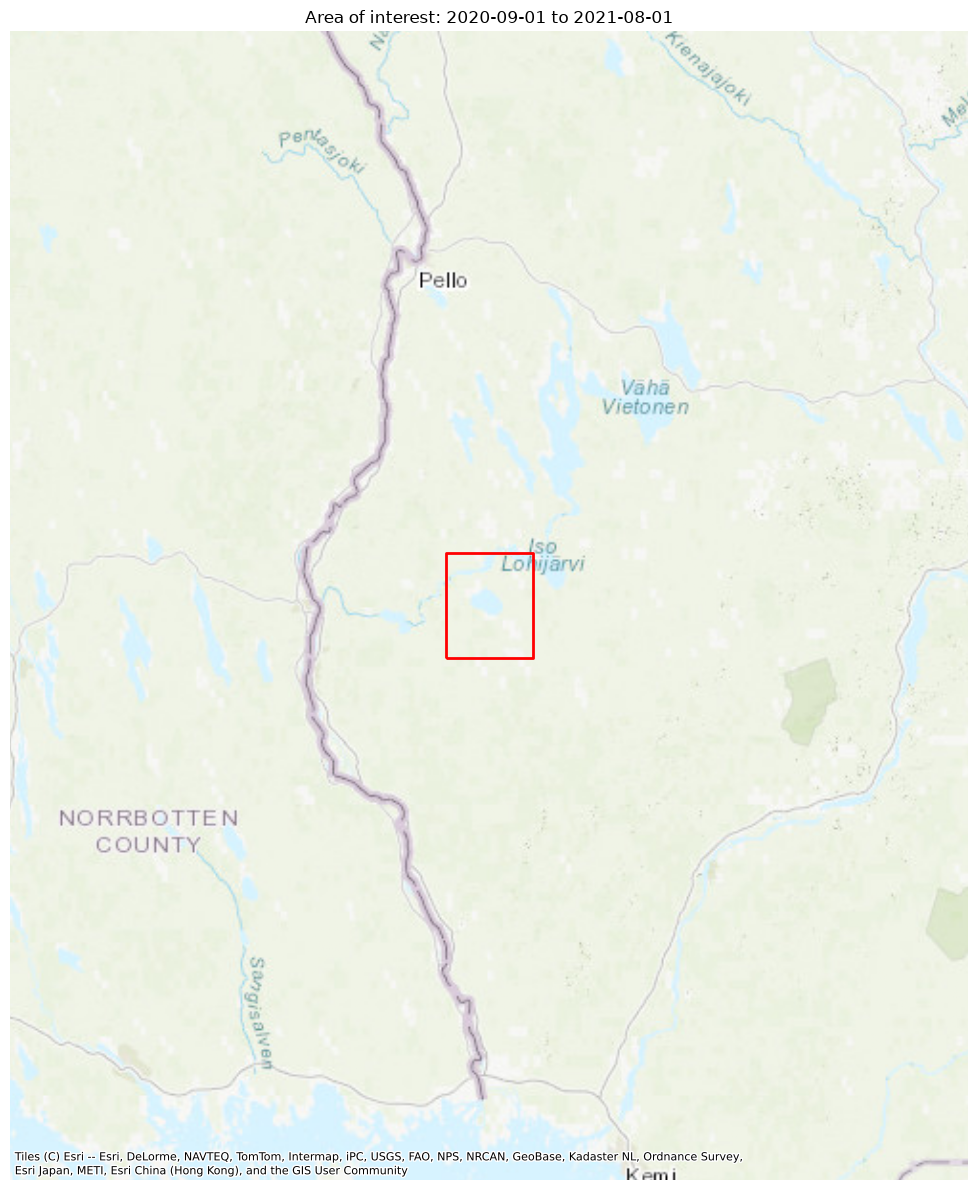

In [8]:
# Show the AOI on a basemap for context.
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx
from shapely import wkt as shapely_wkt

aoi_gdf = gpd.GeoDataFrame({'geometry': [shapely_wkt.loads(aoi)]}, crs='EPSG:4326').to_crs(3857)
minx, miny, maxx, maxy = aoi_gdf.total_bounds
margin_x, margin_y = (maxx - minx) * 5, (maxy - miny) * 5

fig, ax = plt.subplots(figsize=(12, 12))
aoi_gdf.boundary.plot(ax=ax, edgecolor='red', linewidth=2)
ax.set_xlim(minx - margin_x, maxx + margin_x)
ax.set_ylim(miny - margin_y, maxy + margin_y)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zoom=8)  # fixed zoom -- auto zoom was blurry here
ax.set_title(f'Area of interest: {start_date} to {end_date}')
ax.set_axis_off()
plt.tight_layout()
plt.show()


# Section 2 — Visualize and compare WIC S1 vs. WIC S2

Both products classify the same underlying phenomenon (ice vs. open water on rivers and lakes) but from different sensors:
- **WIC S2** classifies ice/water directly from that scene's optical imagery, at 20 m resolution.
- **WIC S1** classifies ice/water using Sentinel-1 radar backscatter, at 60 m resolution, available regardless of cloud cover.

Let's look at both side by side for the same area.


**File naming** (from the WIC Product User Manual):
- WIC S1: `CLMS_WSI_WIC_060m_<TILEID>_<YYYYMMDDTHHmmSS>_<PLATFORM>_<VERSION>_<FILE_ID>.<EXTENSION>`, e.g. `CLMS_WSI_WIC_060m_T34UEG_20170214T044301_S1A_V101_WIC.tif`
- WIC S2: `CLMS_WSI_WIC_020m_<TILEID>_<YYYYMMDDTHHmmSS>_<PLATFORM>_<VERSION>_<FILE_ID>.<EXTENSION>`, e.g. `CLMS_WSI_WIC_020m_T31TCH_20160720T105547_S2A_V100_WIC-QA.tif`

Both sensors use the same `FILE_ID` of `WIC` for the classification layer itself — so we search `*_WIC.tif` in both the S1 and S2 product folders (they're already separated by directory since we queried them separately).

**Class codes** (from the WIC PUM's product content tables):

| Value | WIC S1 | WIC S2 |
|---|---|---|
| 1 | open water | open water |
| 100 | snow-covered or snow-free ice | snow-covered or snow-free ice |
| 200 | radar shadow / layover / foreshortening | *(not used)* |
| 205 | *(not used)* | cloud or cloud shadow |
| 254 | *(not used)* | other features |
| 255 | no data | no data |

**Legend files**: each downloaded product includes a `legend/` subfolder with official `.clr` colormap files (`{dataset_id}_wic.clr` and `{dataset_id}_wic-qa.clr`). We reuse the same `.clr` parsing approach as the snow notebook.


In [9]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
import numpy as np
import glob
import re
import rasterio
from rasterio.mask import mask
from rasterio.warp import transform_bounds
import geopandas as gpd
import contextily as ctx
from shapely.geometry import box


def load_wic_colormap(product_dir, dataset_id, layer='wic'):
    """Load the official colormap from a product's legend/{dataset_id}_{layer}.clr file.
    layer is 'wic' (main classification) or 'wic-qa' (quality summary layer).
    Returns (ListedColormap, {value: label}) or (None, None) if not found.
    """
    clr_path = os.path.join(product_dir, 'legend', f'{dataset_id}_{layer}.clr')
    if not os.path.exists(clr_path):
        return None, None
    try:
        colors = np.zeros((256, 4))
        labels = {}
        with open(clr_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 4:
                    val = int(parts[0])
                    if val < 256:
                        r, g, b = float(parts[1]) / 255., float(parts[2]) / 255., float(parts[3]) / 255.
                        a = float(parts[4]) / 255. if len(parts) > 4 else 1.0
                        colors[val] = [r, g, b, a]
                        label_start_idx = 5 if len(parts) > 5 and parts[4].isdigit() else 4
                        if len(parts) > label_start_idx:
                            labels[val] = " ".join(parts[label_start_idx:])
        return ListedColormap(colors), labels
    except (ValueError, OSError) as e:
        print(f"Error loading colormap from {clr_path}: {e}")
        return None, None


In [10]:
# Download a small example window instead of the whole season -- Sections 2 and 3 only ever look
# at one date each, so there's no need to have the full season downloaded by this point. (Section 4
# downloads the full season separately, once it knows which lake to scope the query to.)
MIDWINTER_TARGET = datetime(2021, 3, 15)
WINDOW_DAYS = 14  # wide enough to include an informative windy scene for Section 3 (see below)
window_start = (MIDWINTER_TARGET - timedelta(days=WINDOW_DAYS)).strftime("%Y-%m-%d")
window_end = (MIDWINTER_TARGET + timedelta(days=WINDOW_DAYS)).strftime("%Y-%m-%d")

print(f"Querying WIC S1/S2 for {window_start} to {window_end}...")
params_wics1_example = build_params(wics1['dataset_id'], aoi, window_start, window_end)
results_wics1_example = execute_request(params_wics1_example)
params_wics2_example = build_params(wics2['dataset_id'], aoi, window_start, window_end)
results_wics2_example = execute_request(params_wics2_example)

example_results = [("WIC S1", r) for r in results_wics1_example] + [("WIC S2", r) for r in results_wics2_example]
num_downloads = 1
pbar = tqdm(example_results, desc="Downloading example window", unit="product")
for label, product in pbar:
    pbar.set_postfix_str(f"{label} {product['Name']}")
    if num_downloads % 3 == 0:
        access_token = get_access_token(credentials["username"], credentials["password"], verbose=False)
        headers = {"Authorization": f"Bearer {access_token}"}
    num_downloads = download_products(product, headers, num_downloads, verbose=False)

s1_dirs = sorted([os.path.join(PRODUCTS_DIR, r['Name']) for r in results_wics1_example
                   if os.path.isdir(os.path.join(PRODUCTS_DIR, r['Name']))])
s2_dirs = sorted([os.path.join(PRODUCTS_DIR, r['Name']) for r in results_wics2_example
                   if os.path.isdir(os.path.join(PRODUCTS_DIR, r['Name']))])
print(f"Example window ({window_start} to {window_end}): {len(s1_dirs)} WIC S1 + {len(s2_dirs)} WIC S2 products.")


Querying WIC S1/S2 for 2021-03-01 to 2021-03-29...
Number of results: 18
Number of results: 10


Example window (2021-03-01 to 2021-03-29): 18 WIC S1 + 10 WIC S2 products.


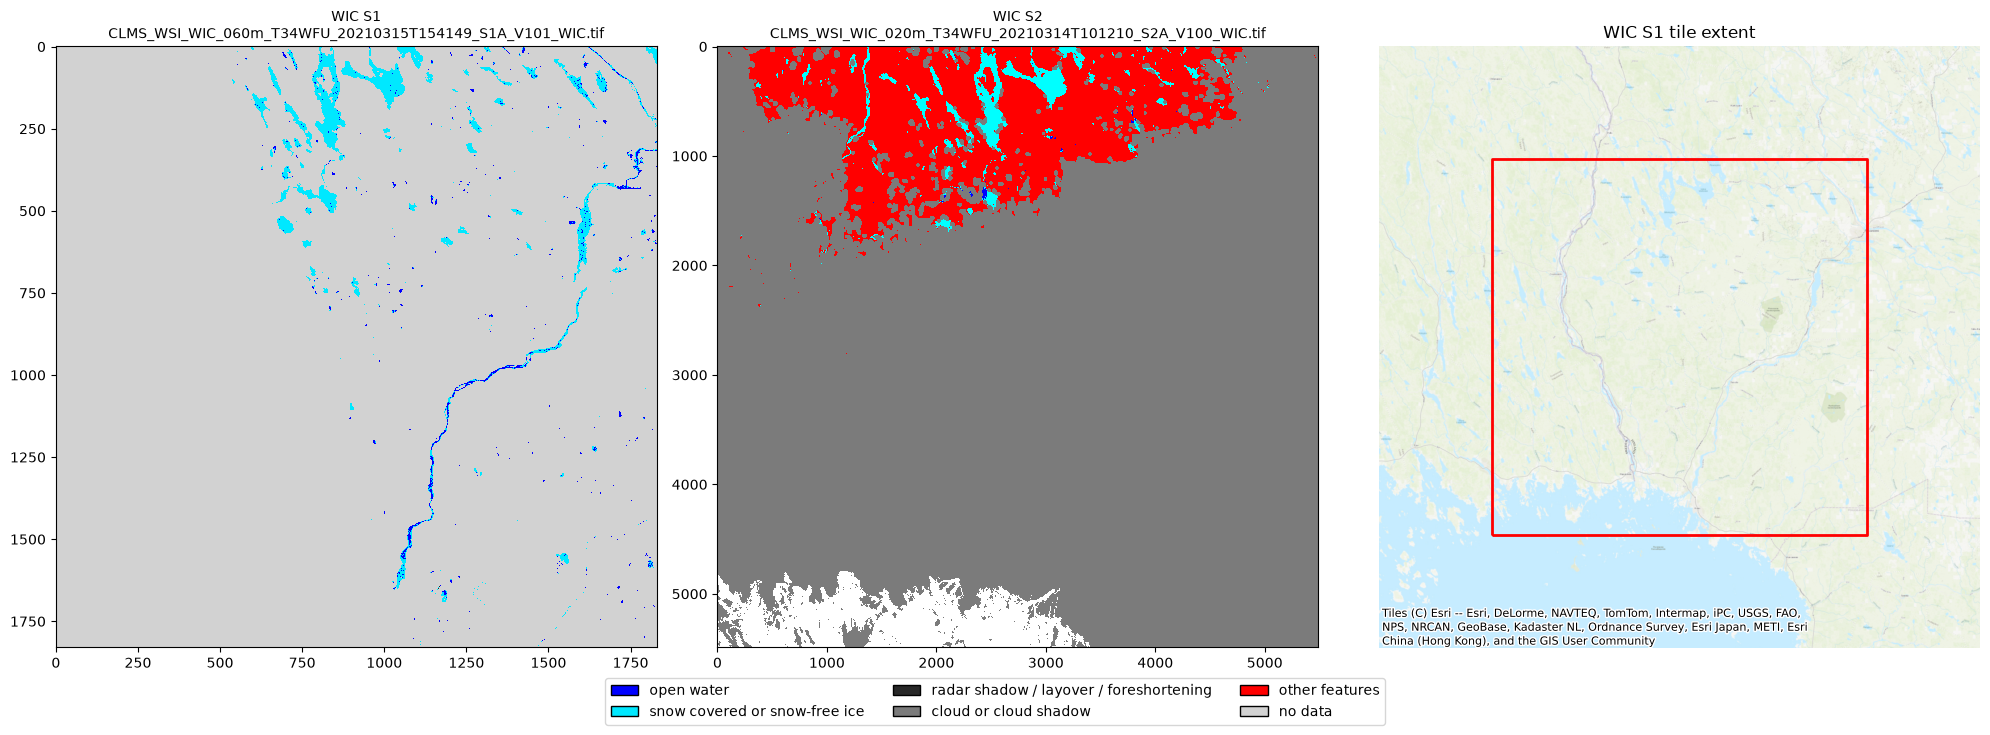

In [11]:
# Pick one WIC S1 product and one WIC S2 product to compare, both close to MIDWINTER_TARGET
SCENE_DATE_RE = re.compile(r'(\d{8}T\d{6})')


def pick_closest_to_date(dirs, target):
    best_dir, best_diff = None, None
    for d in dirs:
        m = SCENE_DATE_RE.search(os.path.basename(d))
        if not m:
            continue
        dt = datetime.strptime(m.group(1), "%Y%m%dT%H%M%S")
        diff = abs((dt - target).total_seconds())
        if best_diff is None or diff < best_diff:
            best_dir, best_diff = d, diff
    return best_dir


fig, axes = plt.subplots(1, 3, figsize=(20, 7))
tile_bounds_3857 = None  # filled in from the WIC S1 raster below, for the extent map on the right

for ax, dirs, label, dataset_id in zip(axes[:2], [s1_dirs, s2_dirs], ['WIC S1', 'WIC S2'],
                                        [wics1['dataset_id'], wics2['dataset_id']]):
    ax.set_facecolor('white')
    if not dirs:
        ax.set_title(f"{label}: no downloaded products found")
        ax.axis('off')
        continue

    product_dir = pick_closest_to_date(dirs, MIDWINTER_TARGET) or dirs[0]
    wic_file = glob.glob(os.path.join(product_dir, '*_WIC.tif'))
    if not wic_file:
        ax.set_title(f"{label}: WIC raster not found in {product_dir}")
        ax.axis('off')
        continue

    cmap, class_labels = load_wic_colormap(product_dir, dataset_id, layer='wic')
    with rasterio.open(wic_file[0]) as src:
        band = src.read(1)
        if label == 'WIC S1':
            # Tile extent for the context map on the right -- taken straight from this WIC S1
            # raster's own footprint (its CRS/bounds), reprojected to Web Mercator to draw on a
            # contextily basemap.
            tile_bounds_3857 = transform_bounds(src.crs, "EPSG:3857", *src.bounds)
        if cmap is not None:
            ax.imshow(band, cmap=cmap, vmin=0, vmax=255, interpolation='nearest')
        else:
            ax.imshow(band, cmap='Blues', interpolation='nearest')
            print(f"No legend found for {label}, falling back to a generic colormap.")
    ax.set_title(f'{label}\n{os.path.basename(wic_file[0])}', fontsize=10)

# Build a shared legend by merging BOTH sensors' .clr files -- S1 and S2 use disjoint class sets
# (e.g. 200 = radar shadow is S1-only, 205 = cloud/cloud shadow is S2-only), so a legend built
# from only one of them would leave the other's classes unlabeled in the plot above.
legend_entries = {}  # value -> (rgb, label)
for dirs, dataset_id in [(s1_dirs, wics1['dataset_id']), (s2_dirs, wics2['dataset_id'])]:
    if not dirs:
        continue
    clr_path = os.path.join(dirs[0], 'legend', f'{dataset_id}_wic.clr')
    if not os.path.exists(clr_path):
        continue
    with open(clr_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 4:
                val = int(parts[0])
                rgb = (int(parts[1]) / 255., int(parts[2]) / 255., int(parts[3]) / 255.)
                label_start_idx = 5 if len(parts) > 5 and parts[4].isdigit() else 4
                lbl = " ".join(parts[label_start_idx:]) if len(parts) > label_start_idx else str(val)
                legend_entries.setdefault(val, (rgb, lbl))

if legend_entries:
    patches = [mpatches.Patch(facecolor=rgb, edgecolor='black', label=lbl)
               for rgb, lbl in (legend_entries[v] for v in sorted(legend_entries))]
    fig.legend(handles=patches, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))

# Third panel: where is this tile? Its footprint (from the WIC S1 raster above), on a basemap.
ax_map = axes[2]
if tile_bounds_3857 is not None:
    minx, miny, maxx, maxy = tile_bounds_3857
    tile_gdf = gpd.GeoDataFrame({'geometry': [box(minx, miny, maxx, maxy)]}, crs='EPSG:3857')
    tile_gdf.boundary.plot(ax=ax_map, edgecolor='red', linewidth=2)
    margin_x, margin_y = (maxx - minx) * 0.3, (maxy - miny) * 0.3
    ax_map.set_xlim(minx - margin_x, maxx + margin_x)
    ax_map.set_ylim(miny - margin_y, maxy + margin_y)
    ctx.add_basemap(ax_map, source=ctx.providers.Esri.WorldTopoMap, zoom=10)
    ax_map.set_title('WIC S1 tile extent')
    ax_map.set_axis_off()
else:
    ax_map.set_title('Tile extent unavailable')
    ax_map.axis('off')

plt.tight_layout()
plt.show()


# Section 3 — Filter observations using the QAFLAGS quality layer

Both WIC products ship a `_QAFLAGS.tif` layer with bit-encoded quality information. The bit definitions differ between S1 and S2 (S1's QAFLAGS is a uint16 raster; S2's is uint8):

**WIC S1 QAFLAGS bits**: 0 = temporary water, 1 = standing/uncategorized water, 2 = temperature data, 3 = summer day, 4 = imperviousness, 5 = tree cover density, 6 = grassland, 7 = wind speed data, 8 = windy, 15 = inland water.

**WIC S2 QAFLAGS bits**: 0 = hillshade, 1 = presence of water, 2 = potentially misclassified pixels.

We demonstrate with **WIC S1, bit 8 (windy)** and **bit 0 (temporary water)**.

**Why the windy flag matters**: wind moves the water surface, and the resulting roughness changes how the surface scatters the radar signal. The SAR-based classification can then interpret that signal as ice, producing a false alarm over open water. The windy flag marks the pixels where this can happen, so they can be excluded when ice presence matters.

**Why the temporary water flag matters**: this flag marks pixels classified as ephemeral/seasonal water rather than permanent water. Such pixels may not be covered by water on the sensing date (for example, seasonally flooded or dried-out areas), so their water/ice class does not necessarily describe the lake itself. Keeping only the permanent-water pixels (flag excluded) restricts the analysis to the area that is actually water-covered.

We reuse the same `s1_dirs` downloaded in Section 2 (the ±1-week window around `MIDWINTER_TARGET`), and look within it for the scene where the windy flag is most informative (neither ~0% nor ~100% of the lake's water pixels) — windy is a rare event in this AOI, so most individual scenes have none at all. For temporary water, we show the permanent-water pixels (the flag excluded) — most of the lake's water pixels should be permanent.


Scanning WIC S1 for an informative windy scene:   0%|          | 0/18 [00:00<?, ?scene/s]

Using CLMS_WSI_WIC_060m_T34WFU_20210301T155830_S1A_V101: 65.4% of water/ice pixels flagged windy, 4.3% flagged temporary water


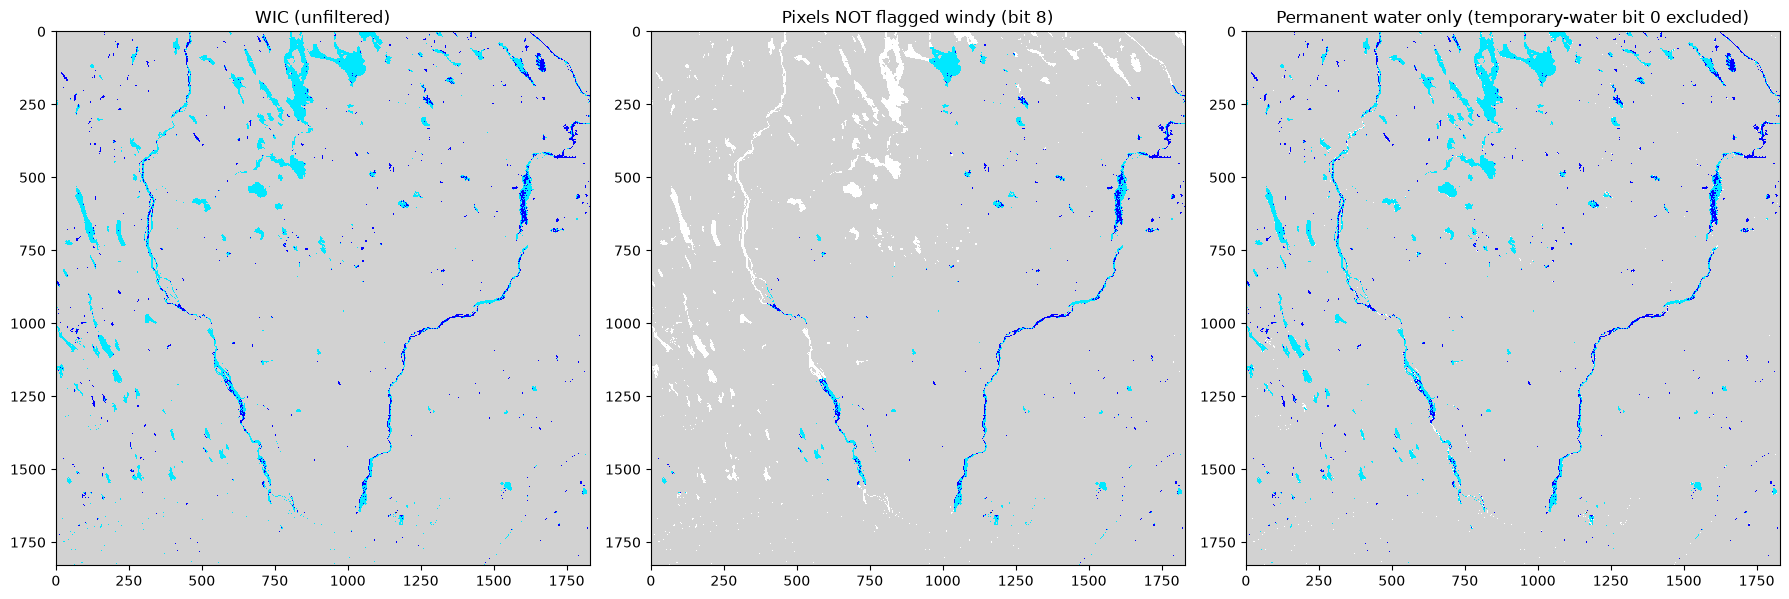

In [12]:
# QAFLAGS filtering demo: WIC S1, bit 8 = windy and bit 0 = temporary water
QA_BIT_WINDY = 8
QA_BIT_TEMP_WATER = 0
QAFLAGS_TARGET_DATE = MIDWINTER_TARGET  # same example date as Section 2

if s1_dirs:
    # Windy is rare, so pick the scene where it's most informative (15-85% of water/ice pixels), closest to the target date.
    best_date_diff, best_dir = None, None
    for product_dir in tqdm(s1_dirs, desc="Scanning WIC S1 for an informative windy scene", unit="scene"):
        wic_file = glob.glob(os.path.join(product_dir, '*_WIC.tif'))
        qa_file = glob.glob(os.path.join(product_dir, '*_QAFLAGS.tif'))
        m = re.search(r'(\d{8}T\d{6})', os.path.basename(product_dir))
        if not wic_file or not qa_file or not m:
            continue
        dt = datetime.strptime(m.group(1), "%Y%m%dT%H%M%S")
        with rasterio.open(wic_file[0]) as src_wic, rasterio.open(qa_file[0]) as src_qa:
            wic_data = src_wic.read(1)
            qa_data = src_qa.read(1)
        water_mask = (wic_data == 1) | (wic_data == 100)  # open water or ice, per the WIC PUM
        if water_mask.sum() < 1000:
            continue
        windy_frac = float(((qa_data >> QA_BIT_WINDY) & 1)[water_mask].mean())
        if not (0.15 <= windy_frac <= 0.85):
            continue
        diff = abs((dt - QAFLAGS_TARGET_DATE).total_seconds())
        if best_date_diff is None or diff < best_date_diff:
            best_date_diff, best_dir = diff, product_dir

    product_dir = best_dir
    if product_dir is None:
        print(f"No scene in the downloaded window had an informative windy fraction (15-85% of water/ice pixels) -- "
              f"try widening WINDOW_DAYS in Section 2.")
    else:
        wic_file = glob.glob(os.path.join(product_dir, '*_WIC.tif'))
        qa_file = glob.glob(os.path.join(product_dir, '*_QAFLAGS.tif'))

        with rasterio.open(wic_file[0]) as src_wic, rasterio.open(qa_file[0]) as src_qa:
            wic_data = src_wic.read(1)
            qa_data = src_qa.read(1)

        water_mask = (wic_data == 1) | (wic_data == 100)
        windy_flag = (qa_data >> QA_BIT_WINDY) & 1
        temp_water_flag = (qa_data >> QA_BIT_TEMP_WATER) & 1
        windy_frac = windy_flag[water_mask].mean()
        temp_water_frac = temp_water_flag[water_mask].mean()
        print(f"Using {os.path.basename(product_dir)}: {windy_frac:.1%} of water/ice pixels flagged windy, "
              f"{temp_water_frac:.1%} flagged temporary water")

        cmap, class_labels = load_wic_colormap(product_dir, wics1['dataset_id'], layer='wic')

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        axes[0].imshow(wic_data, cmap=cmap, vmin=0, vmax=255, interpolation='nearest')
        axes[0].set_title('WIC (unfiltered)')

        wic_not_windy = np.where(windy_flag == 0, wic_data, 0).astype(np.uint8)
        axes[1].imshow(wic_not_windy, cmap=cmap, vmin=0, vmax=255, interpolation='nearest')
        axes[1].set_title(f'Pixels NOT flagged windy (bit {QA_BIT_WINDY})')

        wic_permanent_water = np.where(temp_water_flag == 0, wic_data, 0).astype(np.uint8)
        axes[2].imshow(wic_permanent_water, cmap=cmap, vmin=0, vmax=255, interpolation='nearest')
        axes[2].set_title(f'Permanent water only (temporary-water bit {QA_BIT_TEMP_WATER} excluded)')

        plt.tight_layout()
        plt.show()
else:
    print("No WIC S1 products downloaded — run Section 2 first.")


# Section 4 — Application: estimating freeze-up and break-up dates for a lake

Using a time series of WIC classifications to estimate when a lake froze over (freeze-up) and when it opened again (break-up) during a season — information relevant to hydropower operations, ice-road safety, ferry/shipping schedules, and ecological monitoring.

We use an EU-Hydro lake polygon to select the area to analyze. Once the lake is selected, we download the **full season** for it. The query is scoped to the lake's own footprint rather than the whole-tile AOI used for the Section 2/3 examples, so it only fetches the tiles this lake actually needs.

**When is the lake clipped?** The WIC products are distributed as complete tiles, so the download always returns whole tiles — the lake footprint only decides *which* tiles are selected. The clipping to the lake polygon happens afterwards, locally, on the downloaded rasters (in `compute_ice_fraction`, below).

WIC S1 and WIC S2 are built as separate time series (each sensor observes on its own schedule), and also combined into one series where each product — from either sensor — contributes its own point. WIC S1 is additionally filtered on QAFLAGS before use (see below) to cut down its noise relative to WIC S2.

**You will need**: the EU-Hydro file from the Prerequisites section (set as `EUHYDRO_PATH` in the Auxiliary files check cell above). We read its `InlandWater` layer, with the lake's name in the `NAM` attribute. Set `lake_name_to_select` below once you know which lake you're using.


**EU-Hydro file structure, at a glance** (so it's clear what we're reading and from where):
CLMS offers EU-Hydro either as **one zip per major river basin**, or as a single **whole-Europe zip that just bundles one such basin-zip per basin** — this notebook accepts either (see `EUHYDRO_BASIN_HINT` below). Either way, a basin's zip contains a folder → a `.gdb`, an **Esri File Geodatabase** (a *folder* full of binary index/table files, not a single file — and a basin package can bundle a second, unrelated geodatabase alongside it, e.g. an ancillary drainage-basins layer, so we can't just grab "the first `.gdb` we find"). Inside the real EU-Hydro `.gdb` are twelve feature-class layers; we only read **`InlandWater`** (lake/reservoir polygons). Each polygon carries a `NAM` (name), a `LAKID` (unique ID), and an `AREA` (m²) attribute. We select by `NAM` first, but `NAM` is **not unique** — the same name can belong to several genuinely different lakes (Finland alone has several distinct lakes called "Pyhäjärvi", each elsewhere in the country, each with its own `LAKID` and area). So when a name matches more than one polygon, we narrow down to the row(s) that actually have a valid `LAKID` (a handful of rows have it blank/missing), and if more than one still remains, we pick the largest by `AREA` as the most likely intended lake. This is a heuristic, not a guarantee — if it grabs the wrong one, check the printed candidate count and narrow things down with a more specific `lake_name_to_select` or `EUHYDRO_BASIN_HINT`.


Reading 'InlandWater' layer from auxiliary/EU_hydro_fgdb_eu/euhydro_kemi_v013_FGDB/euhydro_kemi_v013_FGDB/euhydro_kemi_v013.gdb (this can take a moment for large files)...


/home/tanisc/.miniconda/envs/webinar/lib/python3.11/site-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(
/home/tanisc/.miniconda/envs/webinar/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined
  return ogr_read(


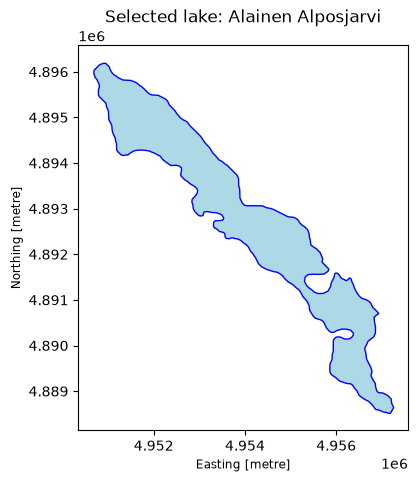

In [13]:
import geopandas as gpd
import fiona
import zipfile

# --- Set this to the lake you want to use (see notebook discussion for candidates) ---
lake_name_to_select = "Alainen Alposjarvi"
# EUHYDRO_PATH can point at EITHER a single-basin download (e.g. euhydro_kemi_v013_FGDB.zip) OR
# the whole-Europe download (e.g. EU_hydro_fgdb_eu.zip, which just bundles one zip per basin).
# If it's the whole-Europe one, set this to a substring identifying your basin (e.g. "kemi") so we
# know which of the ~35 bundled zips to open -- there's no way to infer that from a lake name alone.
EUHYDRO_BASIN_HINT = "kemi"
# ---------------------------------------------------------------------------

EUHYDRO_LAYER = "InlandWater"
EUHYDRO_NAME_COLUMN = "NAM"
EUHYDRO_ID_COLUMN = "LAKID"
EUHYDRO_AREA_COLUMN = "AREA"


def resolve_euhydro_source(path, basin_hint=None):
    """EU-Hydro may be downloaded as a plain .gpkg/.gdb, as a single-basin .zip containing one,
    or as the whole-Europe .zip that just bundles one such basin .zip per major river basin (no
    .gdb directly inside it). Handle all three, extracting only what's needed and only once.
    """
    if not path.lower().endswith(".zip"):
        return path

    with zipfile.ZipFile(path, "r") as zf:
        names = zf.namelist()

    # Whole-Europe bundle: every entry is itself a per-basin .zip, not a .gdb path. Pick the
    # one basin the caller asked for and recurse into it as an ordinary single-basin zip.
    inner_zip_names = [n for n in names if n.lower().endswith(".zip")]
    if inner_zip_names:
        if not basin_hint:
            sample = ", ".join(sorted(inner_zip_names)[:5])
            raise ValueError(
                f"{path} is the whole-Europe EU-Hydro bundle ({len(inner_zip_names)} per-basin zips inside). "
                f"Set EUHYDRO_BASIN_HINT to a substring identifying your basin, e.g. from: {sample}, ..."
            )
        matched = [n for n in inner_zip_names if basin_hint.lower() in n.lower()]
        if not matched:
            raise ValueError(f"No basin zip matching '{basin_hint}' found inside {path}.")
        inner_name = matched[0]
        basin_zip_path = os.path.join(path[:-4], os.path.basename(inner_name))
        if not os.path.exists(basin_zip_path):
            os.makedirs(os.path.dirname(basin_zip_path), exist_ok=True)
            with zipfile.ZipFile(path, "r") as zf, zf.open(inner_name) as src, open(basin_zip_path, "wb") as dst:
                dst.write(src.read())
        return resolve_euhydro_source(basin_zip_path)

    # Single-basin zip: extract (once) and find the .gdb that actually has the layer we need --
    # a basin package can bundle a second, unrelated geodatabase alongside the real EU-Hydro one.
    extract_dir = path[:-4]
    if not os.path.isdir(extract_dir):
        with zipfile.ZipFile(path, "r") as zf:
            zf.extractall(extract_dir)
    candidates = glob.glob(os.path.join(extract_dir, "**", "*.gpkg"), recursive=True) + \
                 glob.glob(os.path.join(extract_dir, "**", "*.gdb"), recursive=True)
    if not candidates:
        raise FileNotFoundError(f"No .gpkg or .gdb found after extracting {path}")
    for candidate in candidates:
        try:
            if EUHYDRO_LAYER in fiona.listlayers(candidate):
                return candidate
        except Exception:
            continue
    raise FileNotFoundError(
        f"None of the geodatabases found under {extract_dir} contain a '{EUHYDRO_LAYER}' layer: {candidates}"
    )


if os.path.exists(EUHYDRO_PATH):
    euhydro_source = resolve_euhydro_source(EUHYDRO_PATH, basin_hint=EUHYDRO_BASIN_HINT)
    print(f"Reading '{EUHYDRO_LAYER}' layer from {euhydro_source} (this can take a moment for large files)...")
    lakes = gpd.read_file(euhydro_source, layer=EUHYDRO_LAYER)
    matches = lakes[lakes[EUHYDRO_NAME_COLUMN] == lake_name_to_select]
    if matches.empty:
        print(f"Lake '{lake_name_to_select}' not found in column '{EUHYDRO_NAME_COLUMN}'. "
              f"Available values (first 20): {sorted(lakes[EUHYDRO_NAME_COLUMN].dropna().unique())[:20]}")
        my_lake = None
    else:
        if len(matches) > 1:
            # NAM is not unique -- the same name can belong to several genuinely different lakes
            # (e.g. Finland has several distinct lakes called "Pyhäjärvi", each its own LAKID and
            # location). Narrow down to the row(s) with a valid LAKID first (a handful of rows have
            # it blank/missing); if more than one still remains, fall back to the largest by AREA
            # as the most likely intended lake -- a heuristic, not a guarantee.
            valid_id = matches[EUHYDRO_ID_COLUMN].notna() & (matches[EUHYDRO_ID_COLUMN].astype(str).str.strip().str.lower().isin(["", "nan", "none"]) == False)
            with_id = matches[valid_id]
            print(f"{len(matches)} features named '{lake_name_to_select}' found, "
                  f"{len(with_id)} with a valid {EUHYDRO_ID_COLUMN}.")
            if not with_id.empty:
                matches = with_id
            if len(matches) > 1:
                print(f"Still {len(matches)} candidates -- using the largest by {EUHYDRO_AREA_COLUMN}. "
                      f"Double-check this is the one you meant, especially if it doesn't overlap your chosen AOI.")
                matches = matches.sort_values(EUHYDRO_AREA_COLUMN, ascending=False)
        my_lake = matches.iloc[[0]]
        fig, ax = plt.subplots(figsize=(5, 5))
        my_lake.plot(ax=ax, facecolor="lightblue", edgecolor="blue")
        plt.title(f"Selected lake: {lake_name_to_select}")
        plt.show()
else:
    print(f"'{EUHYDRO_PATH}' not found. Check the Auxiliary files check cell above and the Prerequisites section.")
    my_lake = None


In [14]:
# Now that a lake is selected, download the full season for it, scoped to the lake's own bounding
# box instead of the whole-tile AOI used for the Section 2/3 examples -- may pull more than one tile if the lake sits near a tile boundary.
def polygon_wkt_from_bounds(bounds):
    minx, miny, maxx, maxy = bounds
    return f"POLYGON(({minx} {miny},{minx} {maxy},{maxx} {maxy},{maxx} {miny},{minx} {miny}))"


if my_lake is not None:
    lake_aoi = polygon_wkt_from_bounds(my_lake.to_crs(4326).total_bounds)

    print(f"Querying WIC S1 for the full season over {lake_name_to_select}...")
    params_wics1_lake = build_params(wics1['dataset_id'], lake_aoi, start_date, end_date)
    results_wics1_lake = execute_request(params_wics1_lake)

    print(f"Querying WIC S2 for the full season over {lake_name_to_select}...")
    params_wics2_lake = build_params(wics2['dataset_id'], lake_aoi, start_date, end_date)
    results_wics2_lake = execute_request(params_wics2_lake)

    lake_results = [("WIC S1", r) for r in results_wics1_lake] + [("WIC S2", r) for r in results_wics2_lake]
    num_downloads = 1
    newly_downloaded = 0
    pbar = tqdm(lake_results, desc="Downloading full season", unit="product")
    for label, product in pbar:
        pbar.set_postfix_str(f"{label} {product['Name']}")
        if num_downloads % 3 == 0:
            access_token = get_access_token(credentials["username"], credentials["password"], verbose=False)
            headers = {"Authorization": f"Bearer {access_token}"}
        before = num_downloads
        num_downloads = download_products(product, headers, num_downloads, verbose=False)
        if num_downloads > before:
            newly_downloaded += 1

    # From here on, s1_dirs/s2_dirs refer to this full-season, lake-scoped download -- overriding
    # the small Section 2/3 example-window download of the same name, which those sections are done with.
    s1_dirs = sorted([os.path.join(PRODUCTS_DIR, r['Name']) for r in results_wics1_lake
                       if os.path.isdir(os.path.join(PRODUCTS_DIR, r['Name']))])
    s2_dirs = sorted([os.path.join(PRODUCTS_DIR, r['Name']) for r in results_wics2_lake
                       if os.path.isdir(os.path.join(PRODUCTS_DIR, r['Name']))])
    print(f"Done: {len(lake_results)} products checked, {newly_downloaded} newly downloaded. "
          f"{len(s1_dirs)} WIC S1 + {len(s2_dirs)} WIC S2 products available for {lake_name_to_select}.")
else:
    print("No lake selected — run the lake-selection cell above first.")

Querying WIC S1 for the full season over Alainen Alposjarvi...
Number of results: 788
Querying WIC S2 for the full season over Alainen Alposjarvi...
Number of results: 155


Done: 943 products checked, 0 newly downloaded. 788 WIC S1 + 155 WIC S2 products available for Alainen Alposjarvi.


### Filtering WIC S1 before computing ice fraction

WIC S1's raw ice fraction is much noisier scene-to-scene than WIC S2's (visible in the raw plot further down), and a large part of that comes from counting pixels that shouldn't really be counted. Before computing WIC S1's ice fraction, we exclude pixels flagged (via the same QAFLAGS layer introduced in Section 3) as **temporary water**, **windy**, **grassland**, or **high tree cover density**, and pixels missing the **temperature** or **wind speed** ancillary data the S1 classification algorithm depends on for that scene — see `s1_qaflags_exclude_mask` in the cell below. No equivalent filter is applied to WIC S2, since its QAFLAGS bits mean something different (see Section 3).


In [15]:
# Class codes from the WIC PUM (Tables 2 and 3) -- same codes for both sensors' core classes
WIC_ICE_VALUE = 100
WIC_WATER_VALUE = 1

# WIC S1 QAFLAGS bits used to filter out unreliable/inapplicable pixels before computing the ice
# fraction (see Section 3 for the full bit table). WIC S1's raw ice fraction is noisy partly because
# it still counts pixels flagged temporary water, windy, grassland, or high tree cover density (all
# of which degrade the radar-based classification), and pixels where the ancillary temperature or
# wind speed data the algorithm relies on was missing for that scene.
QA_S1_BIT_TEMP_WATER = 0
QA_S1_BIT_TEMPERATURE_DATA = 2   # presence flag: 1 = temperature data was available
QA_S1_BIT_TREE_COVER = 5
QA_S1_BIT_GRASSLAND = 6
QA_S1_BIT_WIND_SPEED_DATA = 7    # presence flag: 1 = wind speed data was available
QA_S1_BIT_WINDY = 8


def s1_qaflags_exclude_mask(qa_data):
    """True where a WIC S1 pixel should be excluded from the ice-fraction calculation: flagged
    temporary water, windy, grassland, or high tree cover density, or missing the temperature or
    wind speed ancillary data the S1 classification depends on.
    """
    temp_water = (qa_data >> QA_S1_BIT_TEMP_WATER) & 1
    tree_cover = (qa_data >> QA_S1_BIT_TREE_COVER) & 1
    grassland = (qa_data >> QA_S1_BIT_GRASSLAND) & 1
    windy = (qa_data >> QA_S1_BIT_WINDY) & 1
    has_temperature_data = (qa_data >> QA_S1_BIT_TEMPERATURE_DATA) & 1
    has_wind_speed_data = (qa_data >> QA_S1_BIT_WIND_SPEED_DATA) & 1
    return (temp_water == 1) | (tree_cover == 1) | (grassland == 1) | (windy == 1) | \
           (has_temperature_data == 0) | (has_wind_speed_data == 0)


def compute_ice_fraction(product_dir, lake_gdf, wic_pattern='*_WIC.tif', qa_pattern=None):
    """Clip a WIC raster to the lake polygon and compute the ice fraction among classified water/ice pixels.

    Uses the class codes 1 = open water, 100 = ice (both sensors). Any other value (200/205/254/255,
    i.e. radar shadow, cloud, other features, nodata) is automatically excluded since it's neither of the two
    values we count -- no separate nodata list is needed.

    Pass qa_pattern (e.g. '*_QAFLAGS.tif') to additionally drop WIC S1 pixels flagged unreliable per
    s1_qaflags_exclude_mask before counting -- only meaningful for WIC S1, since WIC S2's QAFLAGS bits
    mean something different (see Section 3).
    """
    wic_file = glob.glob(os.path.join(product_dir, wic_pattern))
    if not wic_file:
        return None, None

    with rasterio.open(wic_file[0]) as src:
        if lake_gdf.crs != src.crs:
            lake_proj = lake_gdf.to_crs(src.crs)
        else:
            lake_proj = lake_gdf
        try:
            out_image, _ = mask(src, lake_proj.geometry, crop=True)
        except ValueError:
            return None, None  # lake does not overlap this tile
        band = out_image[0]

    if qa_pattern is not None:
        qa_file = glob.glob(os.path.join(product_dir, qa_pattern))
        if qa_file:
            with rasterio.open(qa_file[0]) as src_qa:
                qa_out, _ = mask(src_qa, lake_proj.geometry, crop=True)
            exclude = s1_qaflags_exclude_mask(qa_out[0])
            band = np.where(exclude, 255, band)  # treat excluded pixels like nodata

    ice_px = np.sum(band == WIC_ICE_VALUE)
    water_px = np.sum(band == WIC_WATER_VALUE)
    total = ice_px + water_px

    if total == 0:
        return None, wic_file[0]
    return 100.0 * ice_px / total, wic_file[0]


DATE_PATTERN = re.compile(r'(\d{8}T\d{6})')


def extract_date_from_filename(file_path):
    """Extract the acquisition date from a WIC filename, using the
    CLMS_WSI_WIC_<res>_<TILEID>_<YYYYMMDDTHHmmSS>_<PLATFORM>_<VERSION>_<FILE_ID>.<EXT> convention.
    """
    match = DATE_PATTERN.search(os.path.basename(file_path))
    if not match:
        return None
    try:
        return datetime.strptime(match.group(1), "%Y%m%dT%H%M%S")
    except ValueError:
        return None


In [16]:
# Build ice-fraction time series for WIC S1 and WIC S2 (kept as separate points, not merged/averaged).
# WIC S1 is filtered on QAFLAGS (see compute_ice_fraction above); WIC S2's QAFLAGS bits mean something different, so no filter is applied there.
s1_series = []  # list of (date, fraction)
s2_series = []

if my_lake is not None:
    for product_dir in tqdm(s1_dirs, desc="WIC S1 rasters", unit="scene"):
        frac, matched_file = compute_ice_fraction(product_dir, my_lake, qa_pattern='*_QAFLAGS.tif')
        dt = extract_date_from_filename(matched_file) if matched_file else None
        if frac is not None and dt is not None:
            s1_series.append((dt, frac))

    for product_dir in tqdm(s2_dirs, desc="WIC S2 rasters", unit="scene"):
        frac, matched_file = compute_ice_fraction(product_dir, my_lake)
        dt = extract_date_from_filename(matched_file) if matched_file else None
        if frac is not None and dt is not None:
            s2_series.append((dt, frac))

    s1_series.sort()
    s2_series.sort()

    combined_series = sorted(s1_series + s2_series)

    print(f"WIC S1 points: {len(s1_series)}, WIC S2 points: {len(s2_series)}, combined points: {len(combined_series)}")
else:
    print("No lake selected — run the lake-selection cell above first.")


WIC S1 rasters:   0%|          | 0/788 [00:00<?, ?scene/s]

WIC S2 rasters:   0%|          | 0/155 [00:00<?, ?scene/s]

WIC S1 points: 234, WIC S2 points: 48, combined points: 282


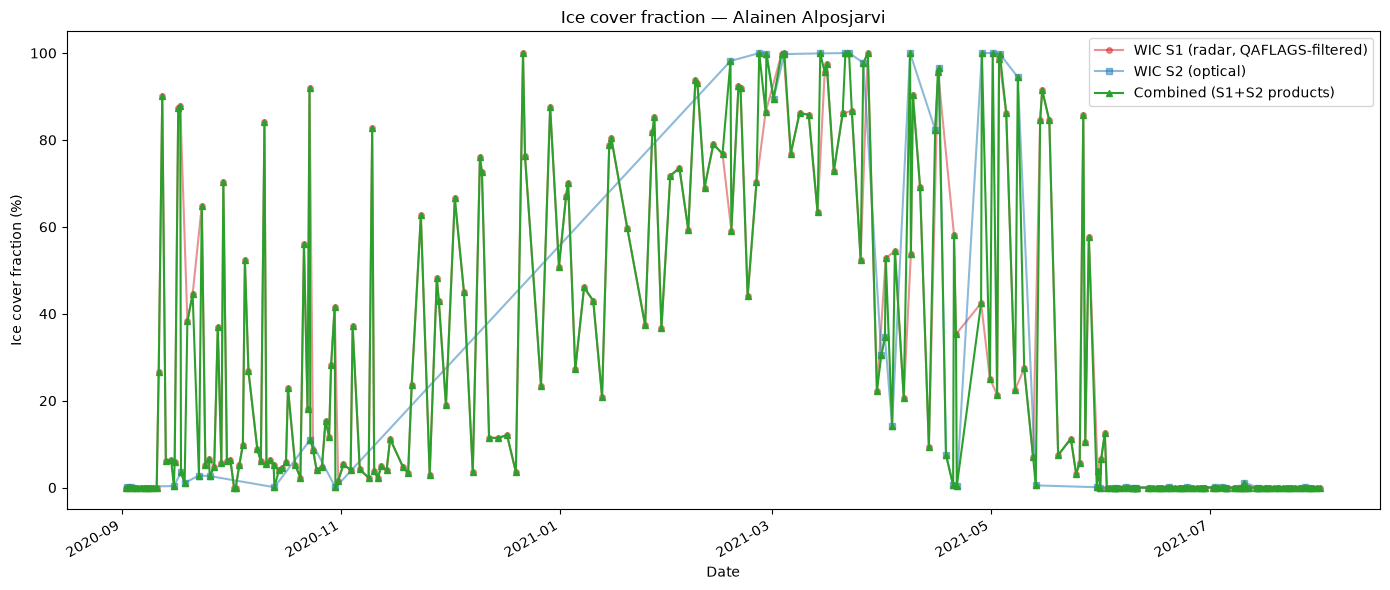

In [17]:
# Plot the WIC S1, WIC S2, and combined series together.
fig, ax = plt.subplots(figsize=(14, 6))

if s1_series:
    d1, f1 = zip(*s1_series)
    ax.plot(d1, f1, 'o-', color='tab:red', alpha=0.5, markersize=4, label='WIC S1 (radar, QAFLAGS-filtered)')

if s2_series:
    d2, f2 = zip(*s2_series)
    ax.plot(d2, f2, 's-', color='tab:blue', alpha=0.5, markersize=4, label='WIC S2 (optical)')

if combined_series:
    dc, fc = zip(*combined_series)
    ax.plot(dc, fc, '^-', color='tab:green', markersize=4, label='Combined (S1+S2 products)')

ax.set_ylabel('Ice cover fraction (%)')
ax.set_xlabel('Date')
ax.set_title(f'Ice cover fraction — {lake_name_to_select}')
ax.legend()
ax.set_ylim(-5, 105)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


### Freeze-up / break-up detection

WIC S1's raw values still swing scene to scene (visible in the plot above) even after the QAFLAGS filtering applied above, which produces false alarms if we run threshold detection directly on it. So we first smooth each series with a trailing moving-window mean (`WINDOW`, below), then apply a threshold-crossing rule to the smoothed series: freeze-up is the first sustained run of `MIN_CONSECUTIVE` scenes at/above `THRESHOLD`%; break-up is the last such run before it falls back below.


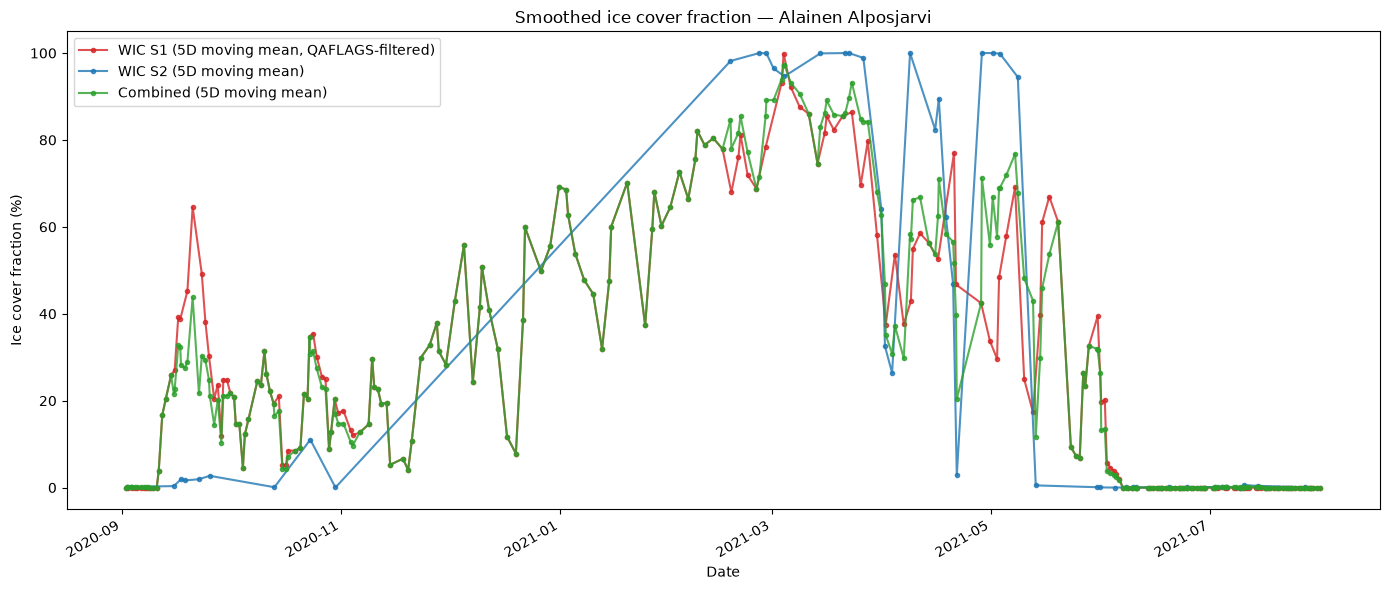

In [18]:
import pandas as pd


def rolling_smooth(series, window='3D'):
    """Smooth an irregular (date, fraction) series with a trailing moving-window mean --
    one smoothed value per original product (not collapsed into monthly buckets), each
    averaging that product's own reading together with the prior `window` of readings.
    """
    if not series:
        return []
    dates, fracs = zip(*series)
    s = pd.Series(fracs, index=pd.to_datetime(dates)).sort_index()
    smoothed = s.rolling(window, min_periods=1).mean()
    return list(zip(smoothed.index.to_pydatetime(), smoothed.values))


WINDOW = '5D'  # trailing 5-day moving mean
s1_smoothed = rolling_smooth(s1_series, window=WINDOW)
s2_smoothed = rolling_smooth(s2_series, window=WINDOW)
combined_smoothed = rolling_smooth(combined_series, window=WINDOW)

fig, ax = plt.subplots(figsize=(14, 6))
for series, color, label in [(s1_smoothed, 'tab:red', f'WIC S1 ({WINDOW} moving mean, QAFLAGS-filtered)'),
                              (s2_smoothed, 'tab:blue', f'WIC S2 ({WINDOW} moving mean)'),
                              (combined_smoothed, 'tab:green', f'Combined ({WINDOW} moving mean)')]:
    if series:
        d, f = zip(*series)
        ax.plot(d, f, 'o-', color=color, markersize=3, alpha=0.8, label=label)

ax.set_ylabel('Ice cover fraction (%)')
ax.set_xlabel('Date')
ax.set_title(f'Smoothed ice cover fraction — {lake_name_to_select}')
ax.legend()
ax.set_ylim(-5, 105)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [19]:
def find_threshold_crossings(series, threshold=50.0, min_consecutive=2):
    """Freeze-up / break-up detector using threshold crossings.
    Finds the first run of `min_consecutive` points at/above threshold (freeze-up),
    and the last such run before it finally drops back below (break-up).
    """
    if len(series) < min_consecutive:
        return None, None

    above = [frac >= threshold for _, frac in series]
    freeze_idx = None
    for i in range(len(above) - min_consecutive + 1):
        if all(above[i:i + min_consecutive]):
            freeze_idx = i
            break

    breakup_idx = None
    for i in range(len(above) - min_consecutive, -1, -1):
        if all(above[i:i + min_consecutive]):
            breakup_idx = i + min_consecutive - 1
            break

    freeze_date = series[freeze_idx][0] if freeze_idx is not None else None
    breakup_date = series[breakup_idx][0] if breakup_idx is not None else None
    return freeze_date, breakup_date


THRESHOLD = 50.0
MIN_CONSECUTIVE = 3
for label, series in [('WIC S1', s1_smoothed), ('WIC S2', s2_smoothed), ('Combined', combined_smoothed)]:
    freeze_date, breakup_date = find_threshold_crossings(series, threshold=THRESHOLD, min_consecutive=MIN_CONSECUTIVE)
    print(f"{label}: estimated freeze-up = {freeze_date}, estimated break-up = {breakup_date}")


WIC S1: estimated freeze-up = 2020-12-29 04:56:35, estimated break-up = 2021-05-19 15:50:07
WIC S2: estimated freeze-up = 2021-02-17 10:12:08, estimated break-up = 2021-05-08 10:12:08
Combined: estimated freeze-up = 2020-12-29 04:56:35, estimated break-up = 2021-05-08 10:12:08


# Wrap-up

That's the end of the live walkthrough. **There's more in this notebook to explore afterward** — an Appendix below with a worked example of the Ice Cover Duration (ICD) annual product, and a short note on the Aggregated Water and Ice Cover (AWIC) product. Feel free to run through those on your own time.


---
# Appendix (self-study — not covered live)


## Ice Cover Duration (ICD)

ICD is an **annual** product: for each pixel in the inland water network, it estimates the number of days that pixel was covered by ice during the hydrological year (1 September – 31 August). It's derived from the Water/Ice Cover (WIC) products across that year.

Below, we query and download one year of ICD for the same AOI used earlier, and map the ice-day count over the lake we selected in Section 4.


In [20]:
# ICD's hydrological year starts 2020-09-01; use a window around it to make sure the product is found.
params_icd = build_params(icd['dataset_id'], aoi, "2020-08-01", "2020-11-30")
results_icd = execute_request(params_icd)

if results_icd:
    access_token = get_access_token(credentials["username"], credentials["password"], verbose=False)
    headers = {"Authorization": f"Bearer {access_token}"}
    num_downloads = 0
    for product in tqdm(results_icd, desc="Downloading ICD", unit="product"):
        num_downloads = download_products(product, headers, num_downloads, verbose=False)
else:
    print("No ICD products found for this AOI/period — adjust the date range or AOI.")


Number of results: 1


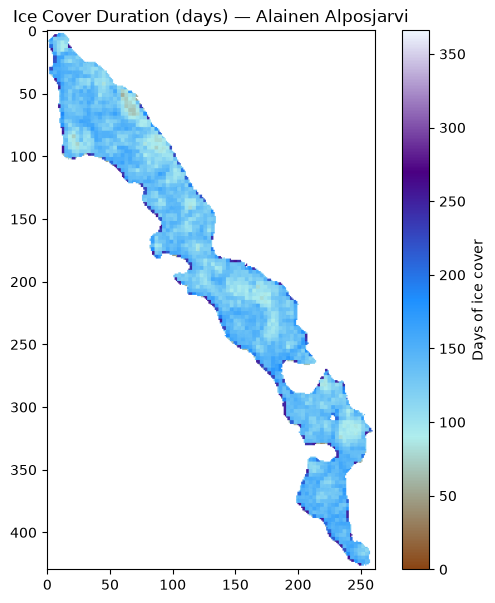

In [21]:
def load_icd_colormap(product_dir, dataset_id, layer='icd'):
    """Load the official ICD colormap from a product's legend/{dataset_id}_{layer}.clr file.
    Unlike WIC's sparse class codes, ICD's .clr is a dense ramp over the full 0-366 day range
    (368 lines, one per day value 0-366 plus a 65535 nodata entry) -- so we build a full-range
    ListedColormap here instead of reusing load_wic_colormap.
    Returns (ListedColormap, vmax) or (None, None) if not found.
    """
    clr_path = os.path.join(product_dir, 'legend', f'{dataset_id}_{layer}.clr')
    if not os.path.exists(clr_path):
        return None, None
    try:
        entries = {}
        with open(clr_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 4:
                    val = int(parts[0])
                    if val > 1000:  # the 65535 nodata sentinel -- not part of the day range
                        continue
                    entries[val] = (int(parts[1]) / 255., int(parts[2]) / 255., int(parts[3]) / 255., 1.0)
        if not entries:
            return None, None
        vmax = max(entries)
        colors = [entries.get(v, (1, 1, 1, 0)) for v in range(vmax + 1)]
        return ListedColormap(colors), vmax
    except (ValueError, OSError) as e:
        print(f"Error loading colormap from {clr_path}: {e}")
        return None, None


# Map the ICD raster, clipped to the lake selected in Section 4
icd_dirs = sorted([os.path.join(PRODUCTS_DIR, r['Name']) for r in results_icd
                    if os.path.isdir(os.path.join(PRODUCTS_DIR, r['Name']))])

if icd_dirs and my_lake is not None:
    product_dir = icd_dirs[0]
    icd_file = glob.glob(os.path.join(product_dir, '*_ICD.tif'))

    if icd_file:
        with rasterio.open(icd_file[0]) as src:
            if my_lake.crs != src.crs:
                lake_proj = my_lake.to_crs(src.crs)
            else:
                lake_proj = my_lake
            try:
                out_image, out_transform = mask(src, lake_proj.geometry, crop=True)
                icd_data = out_image[0]

                # ICD nodata value is 65535 (uint16 max), not negative -- mask on that.
                nodata = src.nodata if src.nodata is not None else 65535
                icd_masked = np.ma.masked_where(icd_data == nodata, icd_data)

                icd_cmap, icd_vmax = load_icd_colormap(product_dir, icd['dataset_id'], layer='icd')

                fig, ax = plt.subplots(figsize=(7, 7))
                if icd_cmap is not None:
                    im = ax.imshow(icd_masked, cmap=icd_cmap, vmin=0, vmax=icd_vmax)
                else:
                    print("No official ICD legend found, falling back to a generic colormap.")
                    im = ax.imshow(icd_masked, cmap='viridis')
                ax.set_title(f'Ice Cover Duration (days) — {lake_name_to_select}')
                fig.colorbar(im, ax=ax, label='Days of ice cover')
                plt.show()
            except ValueError:
                print("Lake does not overlap this ICD tile.")
    else:
        print("ICD raster not found — check file naming in the downloaded product folder.")
else:
    print("No ICD products downloaded, or no lake selected — run the earlier cells first.")


## A note on AWIC (Aggregated Water and Ice Cover)

AWIC is a **vector-based** product also part of the HR-WSI portfolio: rather than raster pixels, it stores daily percent ice/water coverage statistics aggregated per lake and per 10 km river section, in a PostGIS geodatabase queried via a dedicated REST API (not the OData catalogue used elsewhere in this notebook). It's conceptually similar to what we built by hand in Section 4 — a per-water-body ice-fraction time series — but produced and served directly by CLMS rather than computed from raw WIC rasters.

We don't provide a worked example here, but if you want to explore it further, see: https://land.copernicus.eu/en/products/water-bodies/aggregated-water-and-ice-cover-vector-europe-daily
